# Removing the Smooth Shape Correction Tutorial

_How to remove or add the smooth shape correction developed by the mission to level 1B (radiance) products._

In [1]:
import numpy as np                # for scientific computing, good for working with large arrays  
import pandas as pd               # for data analysis, has easy to work with data frames 
import matplotlib.pyplot as plt   # for plotting 
from astropy.io import fits       # for reading / writing / manipulating FITS files 

The smooth shape correction was added to remove temperature-dependent effects in the shape of spectra. It is a set of multiplicative temperature and band specific correction factors that were applied to the mission L1B outputs. For more information on the SSC, see the DPSIS.

Historically, one would have to download an observation-specific smooth shape file from the PDS. To make adding and removing the smooth shape curve (SSC) easier, we combined all SSC data into a single csv file (one for global mode and one for target mode). 

In our pipeline there is an option to turn on or off the smooth shape correction. 

We can load the file of smooth shape curves easily using Pandas. 

In [2]:
ssc_path = ("./tutorial_data/global_ssc.csv")
ssc_df = pd.read_csv(ssc_path)

The resulting dataframe has a column called "obs_id" which you can use to find the correction factors for an observation. The rest of the columns are the correction factors, with the band number in the column name. The number of bands is equivalent to the number of bands in L1B data. So for global mode there are 85 correction factors. 

In [3]:
ssc_df.head()   # .head shows just the top of a Pandas DF 

,obs_id,band_001,band_002,band_003,band_004,band_005,band_006,band_007,band_008,band_009,...,band_076,band_077,band_078,band_079,band_080,band_081,band_082,band_083,band_084,band_085
0,m3g20081118t222604,0.783576,0.823804,0.861004,0.896574,0.912336,0.921938,0.923603,0.926848,0.928661,...,1.057634,1.055953,1.054179,1.052262,1.050241,1.048224,1.047050,1.045862,1.044749,1.043773
1,m3g20081118t223204,0.789332,0.828635,0.865004,0.899813,0.915334,0.924720,0.926361,0.929548,0.931322,...,1.055414,1.053812,1.052122,1.050298,1.048374,1.046456,1.045338,1.044206,1.043148,1.042222
2,m3g20081119t021501,0.871825,0.897888,0.922332,0.946246,0.958303,0.964587,0.965904,0.968245,0.969459,...,1.023593,1.023124,1.022645,1.022142,1.021618,1.021118,1.020798,1.020481,1.020207,1.019996
3,m3g20081119t021733,0.872784,0.898693,0.922998,0.946786,0.958803,0.965050,0.966364,0.968694,0.969903,...,1.023223,1.022768,1.022302,1.021815,1.021307,1.020824,1.020513,1.020206,1.019940,1.019737
4,m3g20081122t224503,0.902520,0.923656,0.943663,0.963523,0.974291,0.979421,0.980617,0.982643,0.983650,...,1.011753,1.011706,1.011677,1.011666,1.011662,1.011690,1.011667,1.011653,1.011671,1.011725


To remove (or add) the smooth shape correction factors, find the row that corresponds to your observation and get the values. 
Then you can divide or add as needed. 

In [4]:
obs_id = 'm3g20090420t191718'
obs_row = ssc_df[ssc_df.iloc[:, 0] == str(obs_id)]            # selecting the row of the dataframe for our specific observation
ssc_factors = obs_row.iloc[0, 1:].to_numpy(dtype=np.float64)  # getting ssc values after the obs_id col, gives an 85-long array

We can view our observation's correction factors in a plot: 

Text(0.5, 0, 'Band')

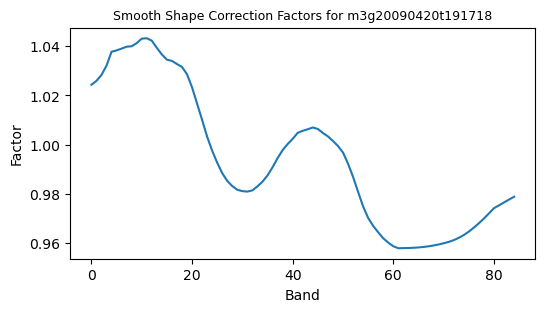

In [5]:
plt.figure(figsize=(6, 3))
plt.plot(ssc_factors)
plt.title(f"Smooth Shape Correction Factors for {obs_id}", fontsize=9)
plt.ylabel("Factor")
plt.xlabel("Band")

In [6]:
# load our l1b data that has the smooth shape correction applied 
path_to_l1b = f"./tutorial_data/{obs_id}_l1b_rdn.fits"
with fits.open(path_to_l1b) as hdul:                          
    l1b_image = hdul[0].data

In [7]:
# divide by ssc factors to remove the correction
l1b_image_no_ssc = l1b_image / ssc_factors[:, np.newaxis, np.newaxis]  # we use np.newaxis to match number of axes of l1b_image                                                                                   

Now we can plot a random pixel spectrum showing before vs after the SSC removal. The effect is relatively small here where radiance is low. 

Text(0.5, 0, 'band')

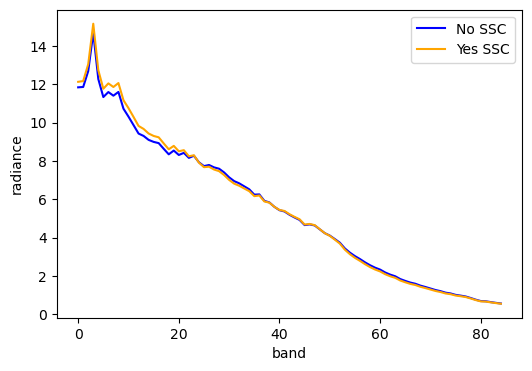

In [8]:
plt.figure(figsize=(6, 4))

line = 286 
sample = 180 

plt.plot(l1b_image_no_ssc[:, line, sample], color='blue', label='No SSC')
plt.plot(l1b_image[:, line, sample], color='orange', label='Yes SSC')
plt.legend()
plt.ylabel("radiance")
plt.xlabel("band")